# Cianjur 25 m grid — v2-9 susceptibility (inference only)

Runs the v2-9 grid fold models (`soil_conditioned_v2-9`, trained on Makilala **without NDVI**)
over the Cianjur EQ 2022 grid and saves the estimated susceptibility map. There are no landslide
labels on this grid, so this is an estimate, not a validation: no AUC is computed.

Input: `datasets/cianjur_combined.gpkg`, which is `combined_ciajur.gpkg` with its columns renamed
to the `nc_combined.gpkg` names. Values are unchanged by the rename. This notebook then:

1. maps the `nc_combined` names to the model's input names (the same mapping that built
   `nc_mapped.gpkg`),
2. converts Cianjur units to the training units (**section 1: check these before running**),
3. predicts with each fold and writes a multi-band 25 m GeoTIFF plus a preview PNG.

Cells dropped by preprocessing (slope < 10°, missing or nodata inputs, unmapped soil type) are
nodata in the output.

In [7]:
import contextlib
import io
import json
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
os.environ["TF_DETERMINISTIC_OPS"] = "1"

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
import rasterio
from rasterio.transform import from_origin
from tensorflow.keras import Model

from py_files.data import dataframe_to_dataset, preprocessing
from py_files.helpers import add_soil_texture_index, add_soil_type_index_v3
from run_model_v3 import build_model_inputs, find_transforms_manifest, load_trained_model, replay_transforms

CIANJUR_PATH = PROJECT_ROOT / "datasets/cianjur_combined.gpkg"
NC_MAPPING_PATH = PROJECT_ROOT / "datasets/nc_mapped.mapping.json"
TRAINING_PATH = PROJECT_ROOT / "datasets/combined_mapped.gpkg"   # Makilala grid the folds were trained on
MODEL_DIR = PROJECT_ROOT / "outputs/obj2/wetness/v4-Fixed-Recharge/grid/soil_conditioned_v2-9"
FOLDS = [1, 2, 3, 4, 5]
PGA_COL = "PGA2_max"

OUTPUT_TIF = MODEL_DIR / "cianjur_grid_v2-9.tif"
OUTPUT_PNG = MODEL_DIR / "cianjur_grid_v2-9_preview.png"
GRID_CELL_M = 25.0
CHUNK_ROWS = 500_000
NODATA = -9999.0
AUDIT_EVERY_NTH = 20   # the unit audit reads every 20th cell (~300k of 6M)

## 1. Column mapping and unit conversions — **check before running**

The rename to model names is fixed (it reuses `nc_mapped.mapping.json`). The unit conversions
and the soil-type recode are not: Cianjur's rasters come from different sources than North
Cotabato's, and several are on different scales. Section 2 prints Cianjur next to the Makilala
training data after these conversions; a median ratio far from 1 means a conversion is still owed.

| model input | Cianjur raw | Makilala training | default here |
|---|---|---|---|
| `PGA2_max` | 3.5–19.9 | 0.20–0.48 g | /100 (%g → g) |
| `ContributingFactor_mean` | 0–144 | 25–2.6e7 (specific catchment area, m) | ×1 — **unit unknown; strongly affects the output** |
| `SoilThc_mean` | −17847…15434, median 198 | 1.5–43 m | ×0.001 (mm → m) as for the slope units, negatives → nodata — **unconfirmed; strongly affects the output** |
| `Prc_mean` | 0.014–0.072, 9% NaN | 127–232 | ×1000 (m → mm); NaN → training median. **Has no effect on this model** (fixed-recharge wetness; scaling it ×0.01 changes no prediction) |
| `type` | codes 0–14 | `Sandy Clay Loam`, `Undifferentiated` | every code → `Undifferentiated` — **placeholder** |

`BUK_mean` (cg/cm³) and clay / sand / silt (g/kg) are SoilGrids on both sides and pass through
unchanged. The model reads bulk density as cg/cm³ (`bulk_density_unit="cg/cm3"`).

**Coverage:** about 46% of the slope ≥ 10° cells have a *negative* soil thickness. They are
treated as nodata and left out of the map. Fixing the thickness raster is the main way to fill
the gaps.

In [8]:
with open(NC_MAPPING_PATH) as f:
    # {model input: nc_combined column} -> {nc_combined column: model input}
    NC_TO_MODEL = {source: target for target, source in json.load(f)["columns"].items()}
# The no-NDVI v2-9 run has no NDVI input, and Cianjur has no NDVI layer.
NC_TO_MODEL.pop("ndvi_northcotabato_prs92", None)
GRID_INDEX_COLS = ["row", "col"]

# Multiplier applied after renaming. Edit these once each unit is confirmed.
UNIT_CONVERSIONS = {
    "PGA2_max": 1 / 100,              # %g -> g
    "Prc_mean": 1000.0,               # m -> mm (unconfirmed)
    "ContributingFactor_mean": 10000,   # unit unknown; left as-is
    "SoilThc_mean": 0.001,            # mm -> m (unconfirmed)
}

# Raw values that mean "no data" in the Cianjur rasters. They become NaN, so preprocessing
# drops the cell rather than feeding a 0 bulk density or thickness into the FOS denominator.
NODATA_RULES = {
    "Elev_mean": lambda v: v <= 0,
    "BUK_mean": lambda v: v <= 0,
    "Clay_mean": lambda v: v <= 0,
    "Silt_mean": lambda v: v <= 0,
    "Sand_mean": lambda v: v <= 0,
    "SoilThc_mean": lambda v: v < 0,
}

# Inputs this model does not use (they feed only an unused sink), so a missing value should
# not drop the cell: NaN is filled with the training median from the fold-1 manifest.
with open(MODEL_DIR / "v1_cotabato_transforms_fold1.json") as f:
    TRAINING_MEDIANS = json.load(f)["imputation_medians"]
UNUSED_INPUT_FILL = {"Prc_mean": TRAINING_MEDIANS["Prc_mean"]}

# Cianjur soil-map code -> soil type label. Every code not listed gets SOIL_TYPE_DEFAULT; a
# missing code stays NaN and the cell is dropped. Section 2 prints each code's majority USDA
# texture (from clay/silt/sand) as a hint. Training only saw 'Sandy Clay Loam' and
# 'Undifferentiated'; any other label falls to the model's unknown-token embedding.
SOIL_TYPE_DEFAULT = "Undifferentiated"
SOIL_TYPE_RECODE = {}   # e.g. {3: "Clay Loam"}


def to_model_frame(raw):
    # Rename to model inputs, convert units, mask nodata, recode soil type. Returns a new frame.
    missing = sorted(set(NC_TO_MODEL) - set(raw.columns))
    if missing:
        raise KeyError(f"{CIANJUR_PATH.name} is missing nc_combined columns {missing}")
    frame = raw[GRID_INDEX_COLS + list(NC_TO_MODEL)].rename(columns=NC_TO_MODEL)
    converted = {col: frame[col] * factor for col, factor in UNIT_CONVERSIONS.items()}
    frame = frame.assign(**converted)
    masked = {col: frame[col].mask(is_nodata(frame[col])) for col, is_nodata in NODATA_RULES.items()}
    frame = frame.assign(**masked).fillna(UNUSED_INPUT_FILL)
    codes = frame["type"]
    soil_type = codes.map(SOIL_TYPE_RECODE).fillna(SOIL_TYPE_DEFAULT).where(codes.notna())
    return frame.assign(type=soil_type)


def load_chunk(rows):
    # Same steps as run_model_v3.load_and_preprocess, minus the geometry: cells are placed by row/col.
    raw = pyogrio.read_dataframe(CIANJUR_PATH, read_geometry=False,
                                 skip_features=rows.start, max_features=rows.stop - rows.start)
    frame, _, _ = preprocessing(to_model_frame(raw), columns_drop=[])
    frame = add_soil_texture_index(frame)
    frame = add_soil_type_index_v3(frame)
    return frame[frame["BUK_mean"] > 0]

## 2. Unit audit — Cianjur (after conversion) vs Makilala training

Read the `median ratio` column: near 1 means the scales agree. A ratio of 10, 100 or 1000 is
almost always a unit left unconverted. Values far outside the training range are extrapolated
by the model, and the physics inputs (slope, PGA, bulk density, thickness, catchment) enter the
FOS / Newmark equations directly, so a wrong unit there changes the physics, not just the scaling.

In [9]:
AUDIT_COLS = ["Slope_mean", "PGA2_max", "BUK_mean", "Prc_mean", "ContributingFactor_mean",
              "SoilThc_mean", "Elev_mean", "Clay_mean", "Silt_mean", "Sand_mean"]
QUANTILES = [0.01, 0.5, 0.99]

audit_raw = pyogrio.read_dataframe(CIANJUR_PATH, read_geometry=False, where=f"fid % {AUDIT_EVERY_NTH} = 0")
cianjur_sample = to_model_frame(audit_raw)
training = pyogrio.read_dataframe(TRAINING_PATH, read_geometry=False, columns=AUDIT_COLS + ["type"])


def quantile_table(frame, label):
    table = frame[AUDIT_COLS].quantile(QUANTILES).T
    table.columns = [f"{label} p{int(q * 100)}" for q in QUANTILES]
    return table


audit = pd.concat([quantile_table(cianjur_sample, "Cianjur"), quantile_table(training, "Makilala")], axis=1)
audit["median ratio"] = audit["Cianjur p50"] / audit["Makilala p50"]
audit["Cianjur NaN %"] = cianjur_sample[AUDIT_COLS].isna().mean() * 100
print(f"{len(cianjur_sample):,} sampled Cianjur cells, {len(training):,} Makilala training cells")
audit.round(3)

298,733 sampled Cianjur cells, 550,530 Makilala training cells


,Cianjur p1,Cianjur p50,Cianjur p99,Makilala p1,Makilala p50,Makilala p99,median ratio,Cianjur NaN %
Slope_mean,0.000,11.620000,43.353001,0.439000,11.007000,4.711900e+01,1.056,2.428
PGA2_max,0.022,0.064000,0.564000,0.202000,0.311000,5.040000e-01,0.206,0.000
BUK_mean,35.000,104.000000,120.000000,82.000000,115.000000,1.310000e+02,0.904,2.498
Prc_mean,3.999,29.694000,149.412994,126.683998,139.798996,2.287310e+02,0.212,0.000
ContributingFactor_mean,0.000,72560.375000,499328.250000,57.129002,482.571991,1.046814e+06,150.362,0.063
SoilThc_mean,0.000,1.851000,13.766000,2.396000,12.187000,3.545200e+01,0.152,45.091
Elev_mean,0.140,498.524994,1697.129028,103.538002,408.389008,2.053516e+03,1.221,0.557
Clay_mean,118.000,363.000000,451.000000,317.000000,383.000000,4.340000e+02,0.948,2.491
Silt_mean,116.000,370.000000,443.000000,214.000000,276.000000,3.330000e+02,1.341,2.492
Sand_mean,87.000,257.000000,340.000000,296.000000,345.000000,3.870000e+02,0.745,2.493


In [10]:
# Hint for SOIL_TYPE_RECODE: USDA texture of each Cianjur soil-map code, from its clay/silt/sand.
raw_codes = audit_raw[[k for k, v in NC_TO_MODEL.items() if v == "type"][0]]
textures = add_soil_texture_index(cianjur_sample.dropna(subset=["Clay_mean", "Silt_mean", "Sand_mean"]).copy())
texture_by_code = pd.crosstab(raw_codes.loc[textures.index], textures["soil_texture"], normalize="index")
print("Training `type` labels:", training["type"].value_counts().to_dict())
print("Cianjur code counts (sample):", raw_codes.value_counts(dropna=False).to_dict())
(texture_by_code * 100).round(1)

Training `type` labels: {'Sandy Clay Loam': 463535, 'Undifferentiated': 86995}
Cianjur code counts (sample): {6.0: 180438, 3.0: 54715, 5.0: 12246, 4.0: 11670, nan: 10315, 10.0: 9706, 7.0: 4861, 0.0: 4652, 8.0: 4046, 9.0: 3767, 2.0: 1150, 1.0: 1140, 14.0: 12, 11.0: 7, 12.0: 6, 13.0: 2}


soil_texture,Clay,Clay Loam,Loam,Sandy Loam,Silt Loam,Silty Clay,Silty Clay Loam
soil_type,,,,,,,
0.0,3.6,80.5,11.3,0.3,2.7,0.0,1.5
1.0,4.4,86.9,4.6,0.2,3.4,0.0,0.4
2.0,8.3,81.5,4.9,0.6,4.2,0.0,0.6
3.0,7.0,92.1,0.3,0.0,0.6,0.0,0.0
4.0,7.2,90.9,0.6,0.1,1.1,0.0,0.1
5.0,7.7,90.5,0.4,0.1,1.2,0.0,0.1
6.0,17.4,80.0,0.9,0.1,0.7,0.3,0.6
7.0,33.6,61.9,1.5,0.5,2.0,0.0,0.4
8.0,34.5,60.1,1.9,0.6,2.4,0.0,0.6


## 3. Predict with every fold → GeoTIFF

Each fold replays its own transform manifest (`v1_cotabato_transforms_fold{N}.json` next to the
checkpoint). Output bands, all on the Cianjur 25 m grid (EPSG:32748):

| band | value |
|---|---|
| 1 `susceptibility_mean` | mean `final_head` over `FOLDS` |
| 2 `susceptibility_std` | spread across folds (ensemble uncertainty) |
| 3 `cohesion_kpa` | fold-mean cohesion |
| 4 `friction_deg` | fold-mean friction angle |
| 5 `displacement_cm` | fold-mean Newmark displacement |
| 6 `wetness_m` | fold-mean wetness ratio m = h_w/H |

In [11]:
# output -> (model layer, unit conversion)
LAYERS = {
    "susceptibility": ("final_head", lambda v: v),
    "cohesion_kpa": ("cohesion_layer", lambda v: v),
    "friction_deg": ("internal_friction", np.degrees),
    "displacement_cm": ("displacement_layer", lambda v: v),
    "wetness_m": ("m_clip", lambda v: v),
}
BAND_NAMES = ["susceptibility_mean", "susceptibility_std", "cohesion_kpa", "friction_deg",
              "displacement_cm", "wetness_m"]


def load_fold_models(folds):
    # (model, extractor, manifest path) per fold; loaded once, reused for every chunk.
    fold_models = []
    for fold in folds:
        path = MODEL_DIR / f"fold-{fold}-model-v3.keras"
        model = load_trained_model(str(path))
        extractor = Model(model.inputs, {layer: model.get_layer(layer).output for layer, _ in LAYERS.values()})
        manifest = find_transforms_manifest(str(path))
        if manifest is None:
            raise FileNotFoundError(f"No transform manifest for {path.name}")
        fold_models.append((model, extractor, manifest))
    return fold_models


def predict_chunk(frame, fold_models):
    # {output: array (n_folds, n_cells)} for one preprocessed chunk.
    per_fold = {name: [] for name in LAYERS}
    for model, extractor, manifest in fold_models:
        feed = build_model_inputs(replay_transforms(frame, model, manifest), model, pga_col=PGA_COL)
        if len(feed) != len(frame):
            raise ValueError(f"{len(feed):,} model rows vs {len(frame):,} cells — rows no longer line up")
        raw = extractor.predict(dataframe_to_dataset(feed.copy(), shuffle=False, batch_size=8192), verbose=0)
        for name, (layer, convert) in LAYERS.items():
            per_fold[name].append(convert(np.asarray(raw[layer]).reshape(len(feed), -1)[:, 0]))
    return {name: np.stack(values) for name, values in per_fold.items()}


def write_geotiff(path, bands, x0, y1, crs):
    first = next(iter(bands.values()))
    profile = dict(
        driver="GTiff", height=first.shape[0], width=first.shape[1], count=len(bands),
        dtype="float32", crs=crs, transform=from_origin(x0, y1, GRID_CELL_M, GRID_CELL_M),
        nodata=NODATA, compress="deflate", tiled=True,
    )
    with rasterio.open(path, "w", **profile) as dst:
        for band, (name, values) in enumerate(bands.items(), start=1):
            dst.write(np.where(np.isnan(values), NODATA, values).astype("float32"), band)
            dst.set_band_description(band, name)


info = pyogrio.read_info(CIANJUR_PATH, force_total_bounds=True)
x0, _, _, y1 = info["total_bounds"]   # row 0 / col 0 is the top-left cell
grid_rc = pyogrio.read_dataframe(CIANJUR_PATH, read_geometry=False, columns=GRID_INDEX_COLS)
grid_shape = (int(grid_rc["row"].max()) + 1, int(grid_rc["col"].max()) + 1)
bands = {name: np.full(grid_shape, np.nan, dtype="float32") for name in BAND_NAMES}
fold_models = load_fold_models(FOLDS)
n_features, n_predicted = info["features"], 0

for start in range(0, n_features, CHUNK_ROWS):
    # The loaders print per call; keep the log for the first chunk only.
    quiet = contextlib.redirect_stdout(io.StringIO()) if start else contextlib.nullcontext()
    with quiet:
        chunk = load_chunk(slice(start, min(start + CHUNK_ROWS, n_features)))
        if chunk.empty:
            continue
        stacked = predict_chunk(chunk, fold_models)
    rows, cols = chunk["row"].to_numpy(int), chunk["col"].to_numpy(int)
    bands["susceptibility_mean"][rows, cols] = stacked["susceptibility"].mean(axis=0)
    bands["susceptibility_std"][rows, cols] = stacked["susceptibility"].std(axis=0)
    for name in ("cohesion_kpa", "friction_deg", "displacement_cm", "wetness_m"):
        bands[name][rows, cols] = stacked[name].mean(axis=0)
    n_predicted += len(chunk)
    print(f"rows {start:,}-{min(start + CHUNK_ROWS, n_features):,}: {len(chunk):,} cells predicted "
          f"({n_predicted:,} so far)")

write_geotiff(OUTPUT_TIF, bands, x0, y1, info["crs"])
print(f"\n{n_predicted:,} of {n_features:,} cells predicted with folds {FOLDS} -> {OUTPUT_TIF}")

  Replaying transforms from /Users/giogonzales/Documents/ml-prep/mlprep/outputs/obj2/wetness/v4-Fixed-Recharge/grid/soil_conditioned_v2-9/v1_cotabato_transforms_fold1.json (v1_cotabato_fold1): log1p ['Elev_mean', 'BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imputed', 'Sand_mean_was_imputed'], clip ['Elev_mean']
  PGA input 'PGA2_max' <- data 'PGA2_max'. Medians in data: PGA2_max=0.1707, PGA2_max_was_imputed=0.0000
  Categorical 'type': 100.0% of values in the model vocabulary ['Sandy Clay Loam', 'Undifferentiated', '[UNK]']
  Replaying transforms from /Users/giogonzales/Documents/ml-prep/mlprep/outputs/obj2/wetness/v4-Fixed-Recharge/grid/soil_conditioned_v2-9/v1_cotabato_transforms_fold2.json (v1_cotabato_fold2): log1p ['Elev_mean', 'BUK_mean_was_imputed', 'SoilThc_mean_was_imputed', 'PGA2_max_was_imputed', 'Clay_mean_was_imputed', 'Silt_mean_was_imputed', 'Sand_mean_was_imputed'], clip ['Elev_mean']
  PGA input 'PG

## 4. Preview

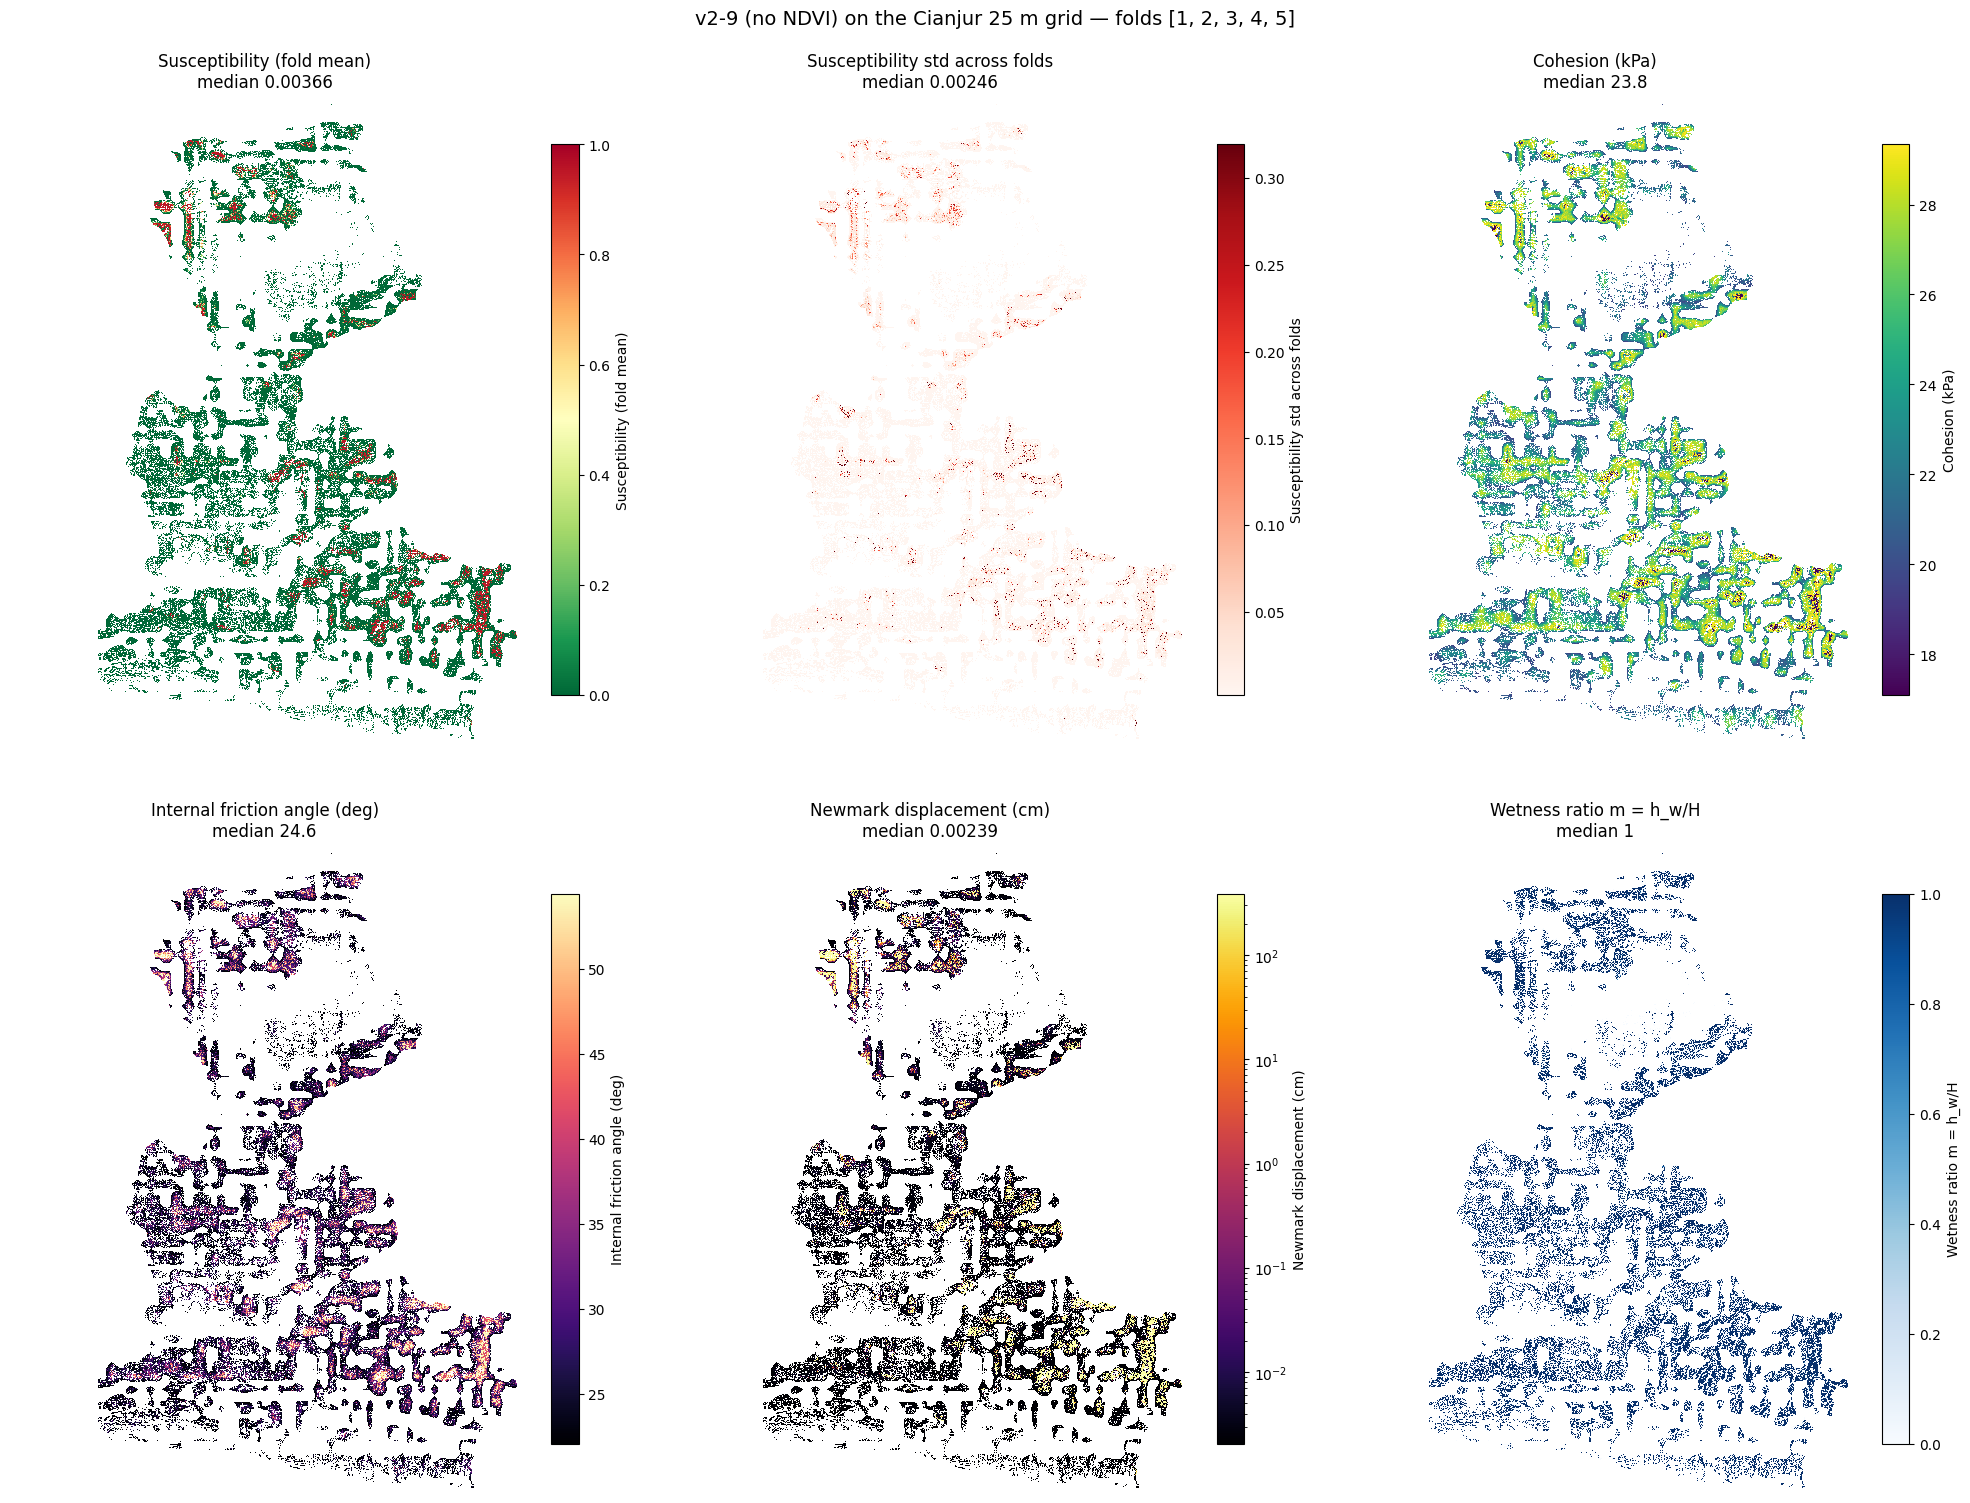

Saved /Users/giogonzales/Documents/ml-prep/mlprep/outputs/obj2/wetness/v4-Fixed-Recharge/grid/soil_conditioned_v2-9/cianjur_grid_v2-9_preview.png


In [12]:
PANELS = {
    "susceptibility_mean": ("Susceptibility (fold mean)", "RdYlGn_r", mcolors.Normalize(0, 1)),
    "susceptibility_std": ("Susceptibility std across folds", "Reds", None),
    "cohesion_kpa": ("Cohesion (kPa)", "viridis", None),
    "friction_deg": ("Internal friction angle (deg)", "magma", None),
    "displacement_cm": ("Newmark displacement (cm)", "inferno", "log"),
    "wetness_m": ("Wetness ratio m = h_w/H", "Blues", None),
}
extent = (x0, x0 + grid_shape[1] * GRID_CELL_M, y1 - grid_shape[0] * GRID_CELL_M, y1)

fig, axes = plt.subplots(2, 3, figsize=(20, 16))
for ax, (name, (label, cmap, norm)) in zip(axes.flat, PANELS.items()):
    values = bands[name]
    lo, hi = np.nanpercentile(values, [1, 99])
    if norm == "log":
        norm = mcolors.LogNorm(vmin=max(lo, 1e-3), vmax=hi)
    elif norm is None:
        norm = mcolors.Normalize(vmin=lo, vmax=hi)
    image = ax.imshow(values, extent=extent, cmap=cmap, norm=norm, interpolation="nearest")
    fig.colorbar(image, ax=ax, shrink=0.7, label=label)
    ax.set_title(f"{label}\nmedian {np.nanmedian(values):.3g}")
    ax.set_axis_off()
fig.suptitle(f"v2-9 (no NDVI) on the Cianjur 25 m grid — folds {FOLDS}", fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_PNG, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved {OUTPUT_PNG}")